# Task 10— Signal Classification: Basic Classifier
## Objective
Generate synthetic AM, FM, and PM signals, extract simple features, classify the signals, and evaluate the predictions.

> **Important limitation:** This is a beginner demonstration for clean, known synthetic signals. It is not a validated real-world RF modulation detector. The features and rules below are intentionally simple and should not be used to identify unknown or noisy RF signals without further validation.

## Learning goals
1. Understand carrier frequency, message frequency, and sampling rate.
2. Generate example AM, FM, and PM signals.
3. Visualize the signals.
4. Extract amplitude and phase-related features.
5. Run a simple rule-based classifier and evaluate it.


## 1. Key terms

- **Carrier frequency (`fc`)**: the carrier's base frequency, in hertz (Hz).
- **Message frequency (`fm`)**: the frequency of the known information pattern used in this demo.
- **Sampling rate (`fs`)**: the number of samples generated per second.
- **Amplitude**: the size/strength of the waveform.
- **Instantaneous frequency**: the estimated frequency at a particular time.
- **Phase**: the position within a repeating cycle.
- **Feature**: a numerical measurement extracted from a signal.
- **Classifier**: a program that uses features to predict a category.

For this notebook, `fc = 50 Hz`, `fm = 5 Hz`, and `fs = 1000 samples/second`. The message is known because this is a controlled simulation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Set the simulation parameters

`np.arange(0, 1, 1/fs)` creates time points from 0 seconds up to (but not including) 1 second. With `fs = 1000`, there are 1000 samples and the sample spacing is 0.001 seconds.

In [2]:
fs = 1000       # Sampling rate: 1000 samples/second
fc = 50         # Carrier frequency: 50 Hz
fm = 5          # Message frequency: 5 Hz
t = np.arange(0, 1, 1/fs)

print("Number of samples:", len(t))
print("Sample spacing (seconds):", 1/fs)
print("Carrier frequency (Hz):", fc)
print("Message frequency (Hz):", fm)

Number of samples: 1000
Sample spacing (seconds): 0.001
Carrier frequency (Hz): 50
Message frequency (Hz): 5


## 3. Generate the known message and the three signals

The message is a 5 Hz cosine.

- **AM:** the message changes the carrier amplitude.
- **FM:** the message controls instantaneous frequency; mathematically, the phase deviation is proportional to the integral of the message.
- **PM:** the message directly controls phase deviation.

These are normalized, illustrative signals. Their parameter values are chosen for demonstration, not to represent a real radio system.

In [3]:
message = np.cos(2 * np.pi * fm * t)

# AM: amplitude follows the message
am = (1 + 0.5 * message) * np.cos(2 * np.pi * fc * t)

# FM: for a sinusoidal message, the phase deviation is sinusoidal
# and proportional to the integral of the message.
fm_index = 2
fm_signal = np.cos(
    2 * np.pi * fc * t + fm_index * np.sin(2 * np.pi * fm * t)
)

# PM: phase deviation follows the message directly
pm_index = 1
pm = np.cos(
    2 * np.pi * fc * t + pm_index * message
)

print("Synthetic AM, FM and PM signals generated.")

Synthetic AM, FM and PM signals generated.


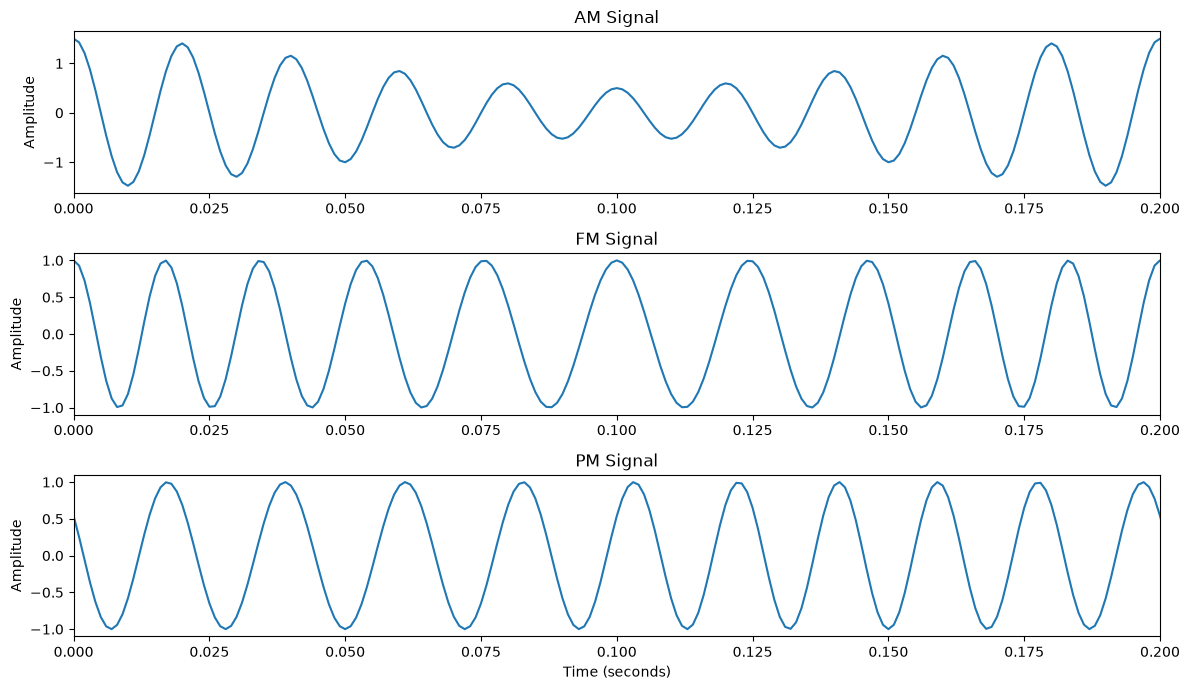

In [4]:
plt.figure(figsize=(12, 7))

plt.subplot(3, 1, 1)
plt.plot(t, am)
plt.title("AM Signal")
plt.ylabel("Amplitude")
plt.xlim(0, 0.2)

plt.subplot(3, 1, 2)
plt.plot(t, fm_signal)
plt.title("FM Signal")
plt.ylabel("Amplitude")
plt.xlim(0, 0.2)

plt.subplot(3, 1, 3)
plt.plot(t, pm)
plt.title("PM Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.2)

plt.tight_layout()
plt.show()

## 4. Extract simple features

This notebook uses:
1. **Amplitude-envelope variation** — standard deviation of the envelope estimated with the Hilbert transform.
2. **Phase/message correlation** — how closely the estimated phase deviation follows the known message.
3. **Phase/integrated-message correlation** — how closely phase deviation follows a sinusoidal pattern corresponding to the integral of this message.

The message is known in this controlled simulation. In a real unknown signal, that assumption may not hold. Correlation features can also be affected by noise, phase estimation errors, and parameter choices.


In [5]:
def extract_features(signal, fs, t, fc, message, fm):
    # Analytic signal gives estimates of envelope and phase
    analytic = hilbert(signal)

    envelope = np.abs(analytic)
    amplitude_variation = np.std(envelope)

    phase = np.unwrap(np.angle(analytic))
    carrier_phase = 2 * np.pi * fc * t
    phase_deviation = phase - carrier_phase

    # For this known cosine message, its integral is proportional
    # to a sine pattern. Use the pattern for a simple comparison.
    integrated_message_pattern = np.sin(2 * np.pi * fm * t)

    # Avoid unstable correlation if either feature is nearly constant.
    if np.std(phase_deviation) < 1e-12:
        corr_message = 0.0
        corr_integrated = 0.0
    else:
        corr_message = np.corrcoef(phase_deviation, message)[0, 1]
        corr_integrated = np.corrcoef(
            phase_deviation, integrated_message_pattern
        )[0, 1]

    # Replace any undefined correlations with zero
    corr_message = 0.0 if not np.isfinite(corr_message) else float(corr_message)
    corr_integrated = 0.0 if not np.isfinite(corr_integrated) else float(corr_integrated)

    return {
        "amplitude_variation": float(amplitude_variation),
        "phase_message_correlation": abs(corr_message),
        "phase_integrated_message_correlation": abs(corr_integrated)
    }

signals = {
    "AM": am,
    "FM": fm_signal,
    "PM": pm
}

features = {}
for label, signal in signals.items():
    features[label] = extract_features(signal, fs, t, fc, message, fm)

for label, values in features.items():
    print(label, values)

AM {'amplitude_variation': 0.3535533905932737, 'phase_message_correlation': 0.0, 'phase_integrated_message_correlation': 0.0}
FM {'amplitude_variation': 2.312424335776879e-08, 'phase_message_correlation': 9.32587340684611e-18, 'phase_integrated_message_correlation': 0.9999999999999999}
PM {'amplitude_variation': 1.1990635087606647e-11, 'phase_message_correlation': 0.9999999999999991, 'phase_integrated_message_correlation': 4.1389114358025917e-16}


## 5. Rule-based baseline classifier

This deliberately simple classifier applies two heuristic rules:
- If amplitude-envelope variation exceeds a chosen threshold, predict AM.
- Otherwise, compare the two phase-correlation features to distinguish this notebook's known FM and PM examples.

**The threshold is a demonstration setting, not a universal value.** The rules are tailored to the generated clean signals and should not be assumed to work for unknown signals. This baseline is useful for learning the classification workflow and evaluating its limitations.

In [6]:
AMPLITUDE_THRESHOLD = 0.1

def classify_from_features(feature_values):
    if feature_values["amplitude_variation"] > AMPLITUDE_THRESHOLD:
        return "AM"

    if (
        feature_values["phase_message_correlation"]
        > feature_values["phase_integrated_message_correlation"]
    ):
        return "PM"

    return "FM"

predictions = {}
for actual_label, feature_values in features.items():
    predictions[actual_label] = classify_from_features(feature_values)
    print(f"Actual: {actual_label} | Predicted: {predictions[actual_label]}")

Actual: AM | Predicted: AM
Actual: FM | Predicted: FM
Actual: PM | Predicted: PM


## 6. Evaluate the predictions

Accuracy is the number of correct predictions divided by the number of test examples. Here there is only one clean example per category, so the accuracy score is only a tiny smoke test, not evidence of general performance.

In [7]:
correct = sum(
    actual == predicted
    for actual, predicted in predictions.items()
)
total = len(signals)
accuracy = 100 * correct / total if total else 0

print(f"Correct predictions: {correct}")
print(f"Total test signals: {total}")
print(f"Accuracy on this tiny synthetic set: {accuracy:.1f}%")

Correct predictions: 3
Total test signals: 3
Accuracy on this tiny synthetic set: 100.0%


## 7. Inspect one feature visually

The envelope can help show why the AM example has changing amplitude. FM and PM ideally keep a constant envelope in these mathematical models.

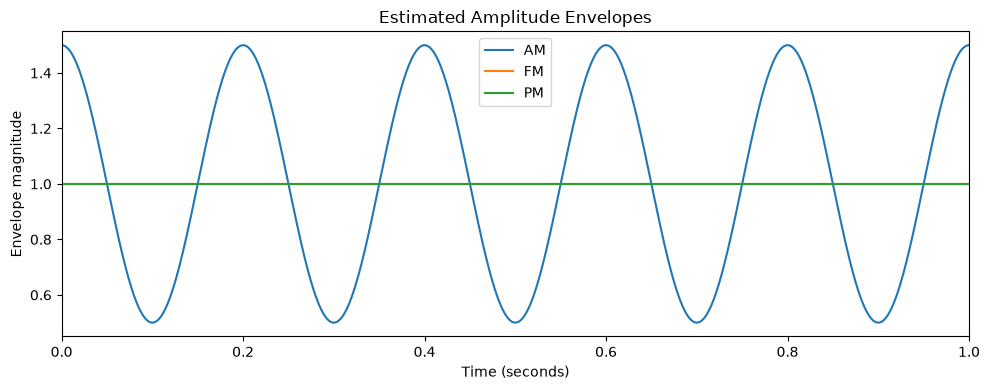

In [8]:
plt.figure(figsize=(10, 4))
for label, signal in signals.items():
    envelope = np.abs(hilbert(signal))
    plt.plot(t, envelope, label=label)

plt.title("Estimated Amplitude Envelopes")
plt.xlabel("Time (seconds)")
plt.ylabel("Envelope magnitude")
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### What this notebook demonstrates
- Creating synthetic AM, FM, and PM signals.
- Estimating amplitude envelopes and phase.
- Building a simple feature-based rule classifier.
- Comparing predictions with known synthetic labels.

